### Doporučené postupy řešení
Úloha je totálně na Vás, Honzovo  řešení obsahuje velmi "prasácké" porovnávání realizované pomocí výpočtu funkce krátkodobé energie s 20ms rámci a se všemi možnými normalizacemi a použití přizpůsobeného filtru. Dosahuje Top 1 accuracy  32.0 %, Top 5 accuracy  44.0 %.

Lepší cesta bude asi parametrizovat signály pomocí spektrogramu, uvědomte si, že není možné přímé srovnání, protože známé signály mají 10s, neznámé 5s a dali jsme si pozor, abychom je vybrali z různých míst známých signálů a ještě přidali trochu šumu a filtrování. Rozhodně doporučujeme si pár příkladů **poslechnout** a během ladění zobrazovat signály, spektorgramy, průběhy podobností, atd - obrázky pak rádi uvidíme v protokolu.

Nad spektrogramy můžete dělat následující:
* rozhodně doporučujeme používat pouze amplitudovou složku.
* uvažte normalizaci (např. průměrným spektrem), abyste se vyhnuli vlivům filtrování.
* uvažte, zda používat i části spektrogramu na velmi nízkých a velmi vysokých frekvencích, kde není nic užitečného
* uvažte, zda používat spektorgram s plným rozlišením, nebo ho snížit použitém širokých frekvenčních kanálů (definovaných lineárně nebo např. pomocí Mel-frekveční osy).

Pro srovnání uvažte:
* posouvání testovacího spektrogramu přes refernční (ale to je hodně hloupá metoda...)
* korelaci
* připůsobené filtrování (což je to samé jako korelace)
* Zájemci mohou zkusit detekci maxim ve spektru a jejich konfigurace a la  Shazaam, viz https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf
* cokoliv jiného, tvořivosti a nápaditosti se meze nekladou
Cokoliv vyvinete vždy oskórujte a zjistěte, zda se 1-best a 5-best přesnost na validační sadě posunula oproti Vaší předchozí verzi.

### Odevzdání
**Termín odevzdání je první pondělí po konci semestru - 15.12.2025, 23:59**
Projekt se odevzdává prostřednictvím informačního systému. Odevzdání bude sestávat ze tří souborů:
  1. **Protokol** ve kterém popíšete, jak jste problém řešili a k jakým výsledkům jste se dopracovali. Protokol bude obsahovat
  * Na začátku Vaše jméno a login...
  * Odůvodnění zvoleného řešení
  * Popis implementace, případných problémů a jejich řešení
  * K jakým výsledkům jste se dopracovali na validační sadě

  Součástí protokolu budou doprovodné obrázky nebo grafy. Pokud použijete obrázky a grafy, které neprodukuje váš program, ale jsou převzaté (např. ilustrativní obrázek, schéma) citujte v souladu s citační etikou. Pokud budete pracovat v Python Notebooku, tvořte protokol textovými poli v notebooku, nestačí jen komentáře v kódu. Protokol bude ve formátu **PDF**. Upozorňujeme, že **pokud bude protokol obsahovat jen kód a výstupy Vašeho kódu, ale žádný popis řešení,  komentáře a hodnocení, bude hodnocen nulou nebo málo body.**

  Pokud budete psát česky nebo slovensky, nazvěte prosím soubor s protokolem  *login.pdf*, kde 'login' je Váš login. Pokud anglicky, pak *login_e.pdf*. Za psaní anglicky nejsou žádné zvláštní body (ani plus ani minus), ale *_e* nám ulehčí rozdělování Vašich řešení opravovačům.

  2. **Program**, kterým jste v rámci řešení projektu vytvořili. Program bude přehledný a rozumně komentovaný. Program bude vypisovat hodnoty a produkovat obrázky uvedené v protokolu.
  * Pokud je program Python notebook na Google Colab, odevzdáte místo programu jen textový soubor s jedinou řádkou - URL Vašeho Python Notebooku. Ten musí být pro opravovače **čitelný** a **spustitelný**.
  * Pokud program bude rozdělen do více souborů, nebo pro jeho spuštění poskytnete návod v souboru README.txt, pak všechny části zabalte do jednoho zip souboru.

  3. **Výsledek - textový soubor eval.txt**. Prosíme neměňte jeho formát, použijte export přiložený k tomuto Python notebooku. Pokud budete pracovat v Google Colab, soubor stáhnete klikem na ikonku složky v levém sloupci dole, pak soubor standardně stáhnete. Budeme používat stejnou skórovací funkci, jakou máte k disposici Vy. Pokud budete experimentovat s více metodami, prosím odevzejte pouze jeden soubor eval.txt vyprodukovaný tou nejlepší metodou a výsledky ostatních metod okomentujte a srovnejte v protokolu.

In [134]:
# needed
import os
import re
import soundfile as sf
from IPython.display import Audio
from IPython.display import display
import numpy as np
# recommended ...
from scipy import signal
from scipy.signal import spectrogram
from scipy.io import wavfile
from scipy.fft import fft, ifft, fftfreq
import scipy.io
import matplotlib.pyplot as plt


In [135]:
'''
# read data
login = "239151"
zip_file = "known" + ".zip"
for name in ("known.zip", "valid.zip", login + ".zip"):
  file = "https://www.fit.vut.cz/study/course/ISS/public/proj2025-26/" + name
  !rm $name
  !wget $file
  !unzip -o -q $name
'''


'\n# read data\nlogin = "239151"\nzip_file = "known" + ".zip"\nfor name in ("known.zip", "valid.zip", login + ".zip"):\n  file = "https://www.fit.vut.cz/study/course/ISS/public/proj2025-26/" + name\n  !rm $name\n  !wget $file\n  !unzip -o -q $name\n'

In [136]:
# load the known data - the function returns a big matrix with all the signals
def load_data (S, dirname, count, no_samples):
  ii = 0
  for one in np.arange(count):
    S[ii], Fs = sf.read(dirname + "/" + str(one) + ".wav")
    ii = ii+1

Fs = 16000
# load known data
N_known = 706; duration_known = 10; no_samples_known = Fs * duration_known
known_signals=np.zeros([N_known, no_samples_known]); load_data(known_signals, "known", N_known, no_samples_known)
# load validation data
N_valid = 50; duration_valid = 5; no_samples_valid = Fs * duration_valid
valid_signals=np.zeros([N_valid, no_samples_valid]); load_data(valid_signals, "valid", N_valid, no_samples_valid)

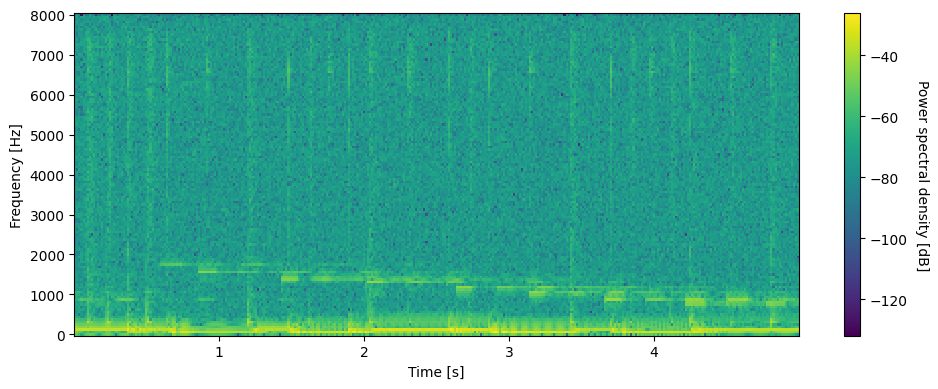

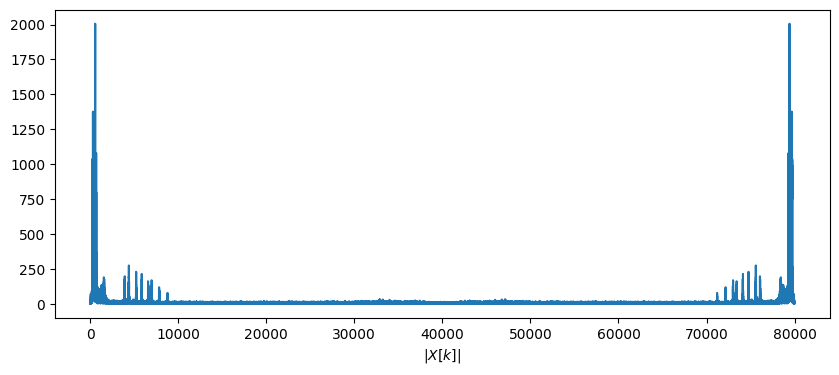

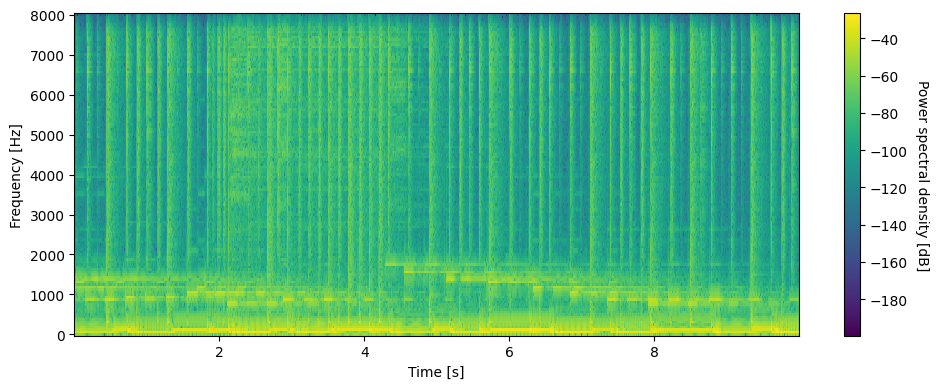

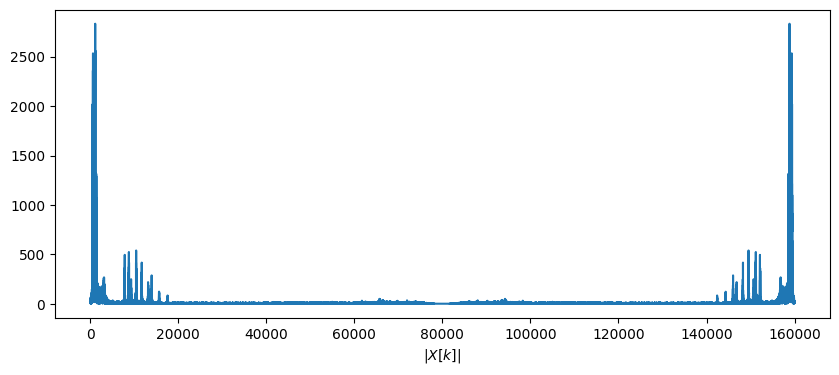

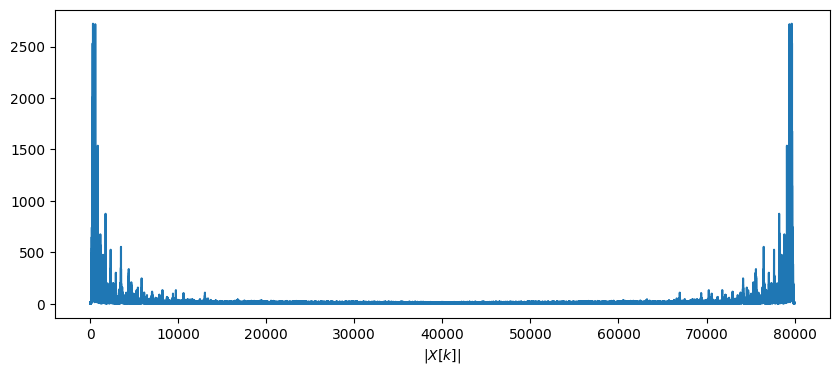

In [137]:
def spectrogram_borrowed(s, Fs):
    f, t, sgr = spectrogram(s, Fs)
    sgr_log = 10 * np.log10(sgr+1e-20)
    plt.figure(figsize=(10,4))
    plt.pcolormesh(t,f,sgr_log)
    plt.gca().set_xlabel('Time [s]')
    plt.gca().set_ylabel('Frequency [Hz]')
    cbar = plt.colorbar()
    cbar.set_label('Power spectral density [dB]', rotation=270, labelpad=15)
    plt.tight_layout()

def fft_borrowed(s):
    N = len(s)
    X = np.fft.fft(s)
    kall = np.arange(0,N)
    Xmag = np.abs(X)

    plt.figure(figsize=(10,4))
    plt.plot(kall,Xmag)
    plt.gca().set_xlabel('$|X[k]|$')

s_valid = valid_signals[0]
s_known = known_signals[182]
spectrogram_borrowed(s_valid, Fs)
fft_borrowed(s_valid)
display(Audio(s_valid, rate=Fs))
spectrogram_borrowed(s_known, Fs)
fft_borrowed(s_known)
display(Audio(s_known, rate=Fs))
fft_borrowed(valid_signals[5])

In [138]:
# YOUR CODE COMES HERE ! Your task is to produce a matrix 50 x 706 with similarity measures

s = valid_signals[45]
def compute_similarity_matrix(N_valid, N_known):
  # complete stupid solution just for testing the evaluation ...
  # the full version will probably have more arguments !
  similarities = np.random.uniform( 0, 1, (N_valid, N_known))
  return similarities


In [139]:
# evaluation - the function produces Top-1 and Top-5 accuracy on validation data
def eval(scores, key):
  indices = np.flip(np.argsort(scores), axis=-1) # we want highest to lowest ...
  #print(scores[0,key[0]], key[0], indices)
  top1acc = np.sum(key == indices[:,0]) / indices.shape[0]
  top5acc = 0
  for ii in range(5):
    top5acc += np.sum(key == indices[:,ii])
  top5acc /=  indices.shape[0]
  return top1acc, top5acc

key = np.loadtxt("valid/key.txt", delimiter = ',', usecols=(1), dtype ='int')

In [140]:
# here comes the computation and evaluation on validation data ...
scores_matrix = compute_similarity_matrix(N_valid, N_known)
#print (key)
top1, top5 = eval(scores_matrix, key)
print("Top 1 accuracy ", top1 * 100, "%, Top 5 accuracy ", top5 * 100, "%" )

Top 1 accuracy  0.0 %, Top 5 accuracy  0.0 %


In [141]:
# NOW on YOUR DATA ! Your task is to produce a matrix 50 x 706 with similarity measures

# load your data
N_eval = 50; duration_eval = 5; no_samples_eval = Fs * duration_eval; login = "239151"
eval_signals=np.zeros([N_eval, no_samples_eval]); load_data(eval_signals, login, N_eval, no_samples_eval)
#display(Audio(valid_signals[45], rate=Fs))

# YOUR CODE COMES HERE ! Your task is to produce a matrix 50 x 706 with similarity measures

# complete stupid dolution just for testing the export of file with results ...
scores_matrix = compute_similarity_matrix(N_valid, N_known)

# export it
np.savetxt("eval.txt", scores_matrix)

# to download it in Google Colab click on the folder icon in the left column, find eval.txt and download it as usually.
